# SAE "Analyse automatique de données" -- Notebook 3 : classification multiclasse

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du classifieur choisi (k plus proche voisin ou arbre de décision) pour effectuer une classification multiclasse des avis ;
2. [Bonus] Effectuer des expérimentations supplémentaires avec d'autres classifieurs (l'autre classifieur vu en cours ou d'autres classifieurs de `scikit-learn`) ;
3. Rédiger une synthèse pour justifier des pré-traitements effectués, du choix du regroupement des notes pour obtenir vos classes et des valeurs des paramètres obtenus pour vos classifieurs. Vous concluerez sur le meilleur choix des pré-traitements, des classes binaires et des paramètres de votre ou vos classifieurs.


Faites attention à la prise en compte du déséquilibre que vous pourriez avoir entre vos classes, en termes de nombre d'avis dans chacune des classes. 
Vous pouvez notamment utiliser le module python `imbalanced-learn` pour tester différentes manières de gérer les déséquilibres entre classes.
	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.
			


## Modules python utilisés

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

## 1. Classification multiclasse avec le classifieur Arbre de décisions

Données chargées. Train: (12652, 3), Test: (3164, 3)

Répartition des classes dans y_train :
rating
1.0    0.136263
2.0    0.124328
3.0    0.239409
4.0    0.250000
5.0    0.250000
Name: proportion, dtype: float64
Démarrage de l'optimisation

Meilleurs paramètres trouvés : {'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_split': 2}
Meilleur score de validation (accuracy) : 0.281

Rapport de classification
              precision    recall  f1-score   support

Très Négatif       0.28      0.31      0.29       431
     Négatif       0.18      0.16      0.17       394
      Neutre       0.28      0.28      0.28       757
     Positif       0.29      0.28      0.29       791
Très Positif       0.35      0.35      0.35       791

    accuracy                           0.29      3164
   macro avg       0.28      0.28      0.28      3164
weighted avg       0.29      0.29      0.29      3164



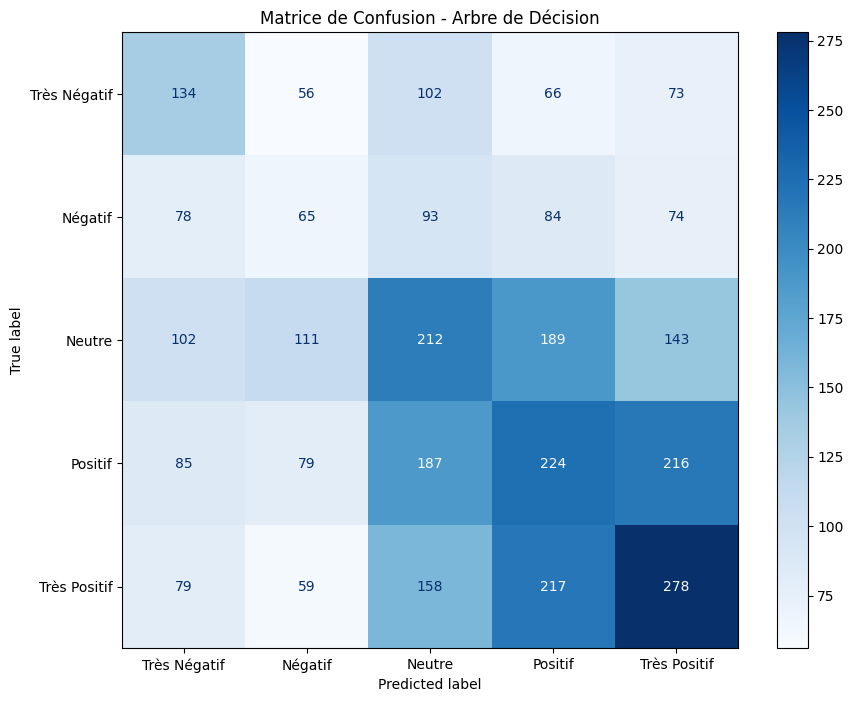

In [2]:
try:
    X_train = pd.read_csv("data/train_test/x_train.csv", index_col=0)
    y_train = pd.read_csv("data/train_test/y_train.csv", index_col=0).squeeze() # squeeze pour en faire une Série
    X_test = pd.read_csv("data/train_test/x_test.csv", index_col=0)
    y_test = pd.read_csv("data/train_test/y_test.csv", index_col=0).squeeze()
    
    print(f"Données chargées. Train: {X_train.shape}, Test: {X_test.shape}")
    
    # Vérification du déséquilibre des classes
    print("\nRépartition des classes dans y_train :")
    print(y_train.value_counts(normalize=True).sort_index())
    
except FileNotFoundError:
    print("Fichiers non trouvés")


classes_noms = ['Très Négatif', 'Négatif', 'Neutre', 'Positif', 'Très Positif']

# ------------------------------------ Classifieur Arbre de décisions -----------------------------------

# Transformateurs pour les colonnes
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=2000, stop_words='english'), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ],
    remainder='drop'
)

# Gestion du déséquilibre
pipeline_dt = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Grille de paramètres à tester
param_grid_dt = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [10, 20, 30, None],
    'classifier__min_samples_split': [2, 10, 20]
}

# Recherche des meilleurs hyperparamètres
print("Démarrage de l'optimisation")
grid_dt = GridSearchCV(pipeline_dt, param_grid_dt, cv=3, scoring='accuracy', n_jobs=-1)
grid_dt.fit(X_train, y_train)

print(f"\nMeilleurs paramètres trouvés : {grid_dt.best_params_}")
print(f"Meilleur score de validation (accuracy) : {grid_dt.best_score_:.3f}")

# Évaluation sur le jeu de test avec le meilleur modèle
best_dt_model = grid_dt.best_estimator_
predictions_dt = best_dt_model.predict(X_test)

print("\nRapport de classification")
print(classification_report(y_test, predictions_dt, target_names=classes_noms))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions_dt, 
    display_labels=classes_noms,
    cmap='Blues',
    ax=ax
)
plt.title("Matrice de Confusion - Arbre de Décision")
plt.show()

## [Bonus] 2. Utilisation d'autres classifieurs multiclasse
 

Démarrage de l'optimisation KNN (peut être long)...
Meilleurs paramètres KNN : {'classifier__metric': 'cosine', 'classifier__n_neighbors': 11, 'classifier__weights': 'distance'}
Meilleur score validation : 0.244

Rapport KNN
              precision    recall  f1-score   support

Très Négatif       0.22      0.34      0.27       431
     Négatif       0.12      0.19      0.15       394
      Neutre       0.29      0.28      0.28       757
     Positif       0.29      0.19      0.23       791
Très Positif       0.34      0.27      0.30       791

    accuracy                           0.25      3164
   macro avg       0.25      0.26      0.25      3164
weighted avg       0.27      0.25      0.26      3164



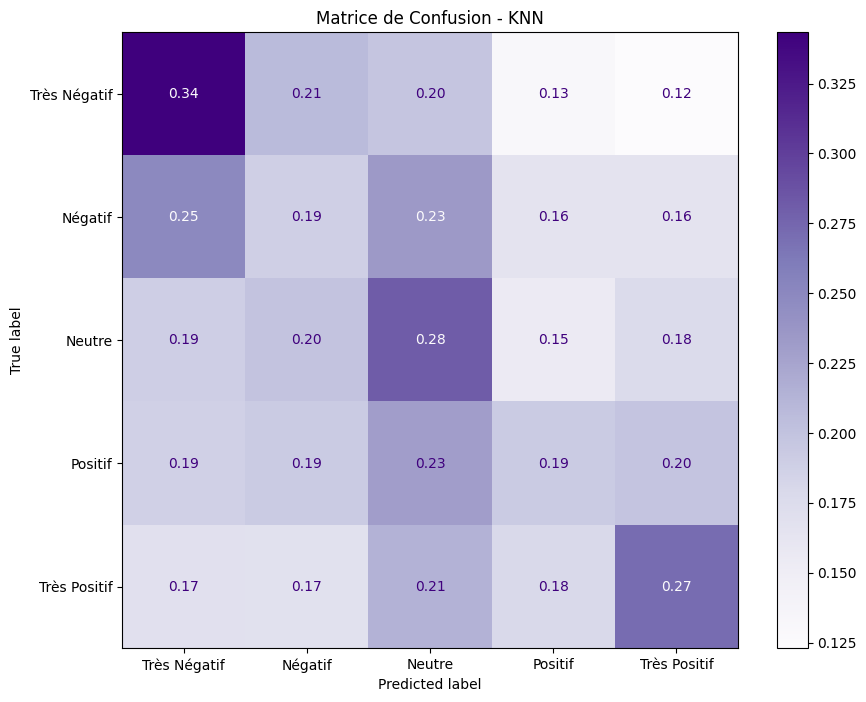

In [3]:
# ------------------------------------ Classifieur KNN -----------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2)), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ], remainder='drop'
)

# --- Pipeline KNN ---
pipeline_knn = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', KNeighborsClassifier()) # On configure les paramètres dans la grille
])

# --- Grille ---
param_grid_knn = {
    'classifier__n_neighbors': [5, 11],
    'classifier__weights': ['distance'],
    'classifier__metric': ['cosine']
}

print("Démarrage de l'optimisation KNN (peut être long)...")
grid_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=3, scoring='accuracy', n_jobs=-1)
grid_knn.fit(X_train, y_train)

print(f"Meilleurs paramètres KNN : {grid_knn.best_params_}")
print(f"Meilleur score validation : {grid_knn.best_score_:.3f}")

# --- Résultats ---
best_knn = grid_knn.best_estimator_
pred_knn = best_knn.predict(X_test)

print("\nRapport KNN")
print(classification_report(y_test, pred_knn, target_names=classes_noms))

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(y_test, pred_knn, display_labels=classes_noms, cmap='Purples', normalize='true', ax=ax, values_format='.2f')
plt.title("Matrice de Confusion - KNN")
plt.show()

Démarrage de l'optimisation Random Forest...
Meilleurs paramètres RF : {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
Meilleur score validation : 0.356

Rapport Random Forest
              precision    recall  f1-score   support

Très Négatif       0.39      0.35      0.37       431
     Négatif       0.20      0.06      0.10       394
      Neutre       0.31      0.36      0.34       757
     Positif       0.32      0.32      0.32       791
Très Positif       0.43      0.54      0.48       791

    accuracy                           0.36      3164
   macro avg       0.33      0.33      0.32      3164
weighted avg       0.34      0.36      0.34      3164



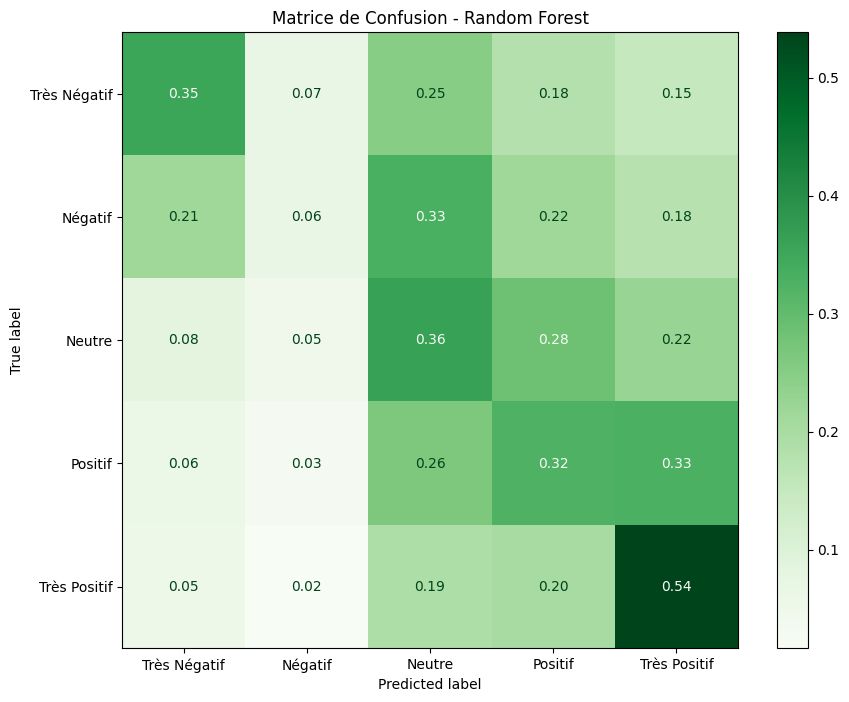

In [4]:
# ------------------------------------ Classifieur Random Forest -----------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2)), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ], remainder='drop'
)

# --- Pipeline Random Forest ---
pipeline_rf = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42))
])

# --- Grille ---
param_grid_rf = {
    'classifier__n_estimators': [100],      # Nombre d'arbres
    'classifier__max_depth': [None, 20],    # Profondeur max (None = apprend tout)
    'classifier__min_samples_leaf': [1, 2]  # Un peu de régularisation
}

print("Démarrage de l'optimisation Random Forest...")
grid_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train, y_train)

print(f"Meilleurs paramètres RF : {grid_rf.best_params_}")
print(f"Meilleur score validation : {grid_rf.best_score_:.3f}")

# --- Résultats ---
best_rf = grid_rf.best_estimator_
pred_rf = best_rf.predict(X_test)

print("\nRapport Random Forest")
print(classification_report(y_test, pred_rf, target_names=classes_noms))

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(y_test, pred_rf, display_labels=classes_noms, cmap='Greens', normalize='true', ax=ax, values_format='.2f')
plt.title("Matrice de Confusion - Random Forest")
plt.show()

Démarrage de l'optimisation Régression Logistique...
Meilleurs paramètres LogReg : {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Meilleur score validation : 0.340

Rapport Régression Logistique
              precision    recall  f1-score   support

Très Négatif       0.34      0.41      0.37       431
     Négatif       0.21      0.27      0.23       394
      Neutre       0.35      0.29      0.32       757
     Positif       0.34      0.31      0.33       791
Très Positif       0.47      0.47      0.47       791

    accuracy                           0.35      3164
   macro avg       0.34      0.35      0.34      3164
weighted avg       0.36      0.35      0.36      3164



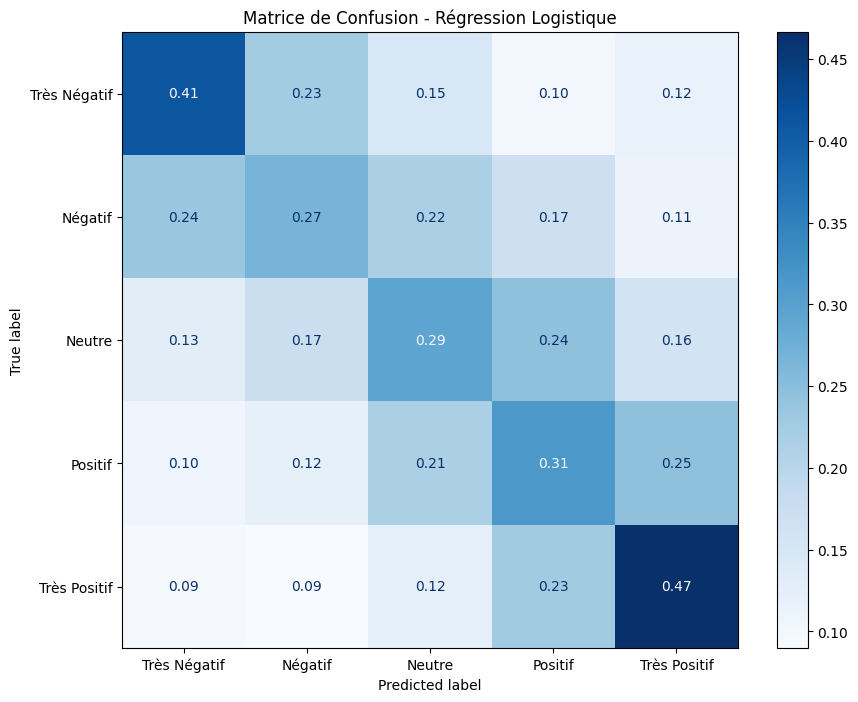

In [5]:
# ------------------------------------ Classifieur LogisticRegression -----------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2)), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ], remainder='drop'
)

# --- Pipeline LogReg ---
pipeline_lr = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# --- Grille ---
param_grid_lr = {
    'classifier__C': [0.1, 1, 10],  # Paramètre clé : force de régularisation
    'classifier__solver': ['lbfgs']
}

print("Démarrage de l'optimisation Régression Logistique...")
grid_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=3, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X_train, y_train)

print(f"Meilleurs paramètres LogReg : {grid_lr.best_params_}")
print(f"Meilleur score validation : {grid_lr.best_score_:.3f}")

# --- Résultats ---
best_lr = grid_lr.best_estimator_
pred_lr = best_lr.predict(X_test)

print("\nRapport Régression Logistique")
print(classification_report(y_test, pred_lr, target_names=classes_noms))

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, display_labels=classes_noms, cmap='Blues', normalize='true', ax=ax, values_format='.2f')
plt.title("Matrice de Confusion - Régression Logistique")
plt.show()

## 3. Synthèse des expérimentations et des résultats obtenus